[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

用经典测量结果控制校正门，验证 Bob 的测量概率和位序。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。

# 量子隐形传态与动态量子线路

**量子线路**：

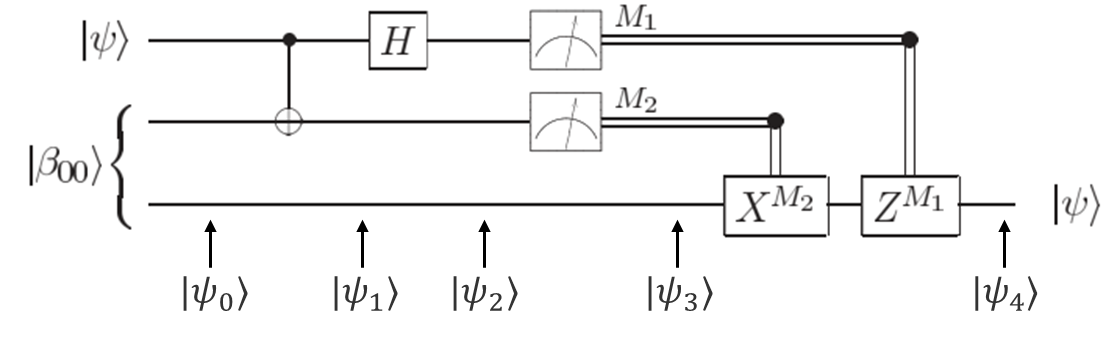

## 第一步：导入必要的包

- RY：用于制备Alice量子比特的初始态
- qif：用于动态量子线路

In [1]:
from numpy import pi
from pyqpanda3.core import H, CNOT, measure, X, Z, QProg
from pyqpanda3.core import RY
from pyqpanda3.core import CPUQVM
from pyqpanda3.core import qif

## 第二步：制备Alice的初态

初始化Alice的未知态: 
$$
|\psi\rangle = \cos\left(\frac{\pi}{3}\right) |0\rangle + \sin\left(\frac{\pi}{3}\right) |1\rangle =  \frac{1}{2} |0\rangle + \frac{\sqrt{3}}{2} |1\rangle
$$

因此，对Alice的量子比特做测量操作，理论上：
$$
\begin{align}
P_0 = \frac{1}{4} \\
P_1 = \frac{3}{4}
\end{align}
$$

In [2]:
prog = QProg(3)

theta = 2 * pi / 3
prog << RY(0, theta)

┌──┐ 
q_0:  |0>─┤RY├ 
          └──┘ 
q_1:  |0>───── 
               
q_2:  |0>───── 
               
 c :   / ═════

## 第三步：准备Alice和Bob的纠缠资源

In [3]:
prog << H(1) << CNOT(1, 2)

┌──┐        
q_0:  |0>─┤RY├ ────── 
          ├─┬┘        
q_1:  |0>─┤H├─ ───*── 
          └─┘  ┌──┴─┐ 
q_2:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

## 第四步：Alice对自己的两个量子比特做联合操作并测量

In [4]:
prog << CNOT(0, 1) << H(0)
prog << measure(0, 0) << measure(1, 1)

┌──┐               ┌─┐   ┌─┐ 
q_0:  |0>─┤RY├ ────── ───*── ┤H├─ ─┤M├ 
          ├─┬┘        ┌──┴─┐ └┬┴┐  └╥┘ 
q_1:  |0>─┤H├─ ───*── ┤CNOT├ ─┤M├ ──╫─ 
          └─┘  ┌──┴─┐ └────┘  └╥┘   ║  
q_2:  |0>───── ┤CNOT├ ────── ──╫─ ──╫─ 
               └────┘          ║    ║  
 c :   / ══════════════════════╩════╩═
                                1    0

## 第五步：Alice将测量结果通过经典信道发送给Bob，Bob根据结果进行校正

**注意**：先作用X门，再作用Z门

In [5]:
x_prog = QProg()
x_prog << X(2)

z_prog = QProg()
z_prog << Z(2)

prog << qif([1]).then(x_prog).qendif()
prog << qif([0]).then(z_prog).qendif()

┌──┐                     ┌─┐     ┌─┐                                  
q_0:  |0>─┤RY├ ────── ───*──────── ┤H├─── ─┤M├─────── ──────────── ─── ──────── 
          ├─┬┘        ┌──┴─┐       └┬┴┐    └╥┘                                  
q_1:  |0>─┤H├─ ───*── ┤CNOT├────── ─┤M├── ──╫──────── ──────────── ─── ──────── 
          └─┘  ┌──┴─┐ ├────┴─────   └╥┼─┐   ║───────┐ ┌──────────  ┌─┐ ───────┐ 
q_2:  |0>───── ┤CNOT├ ┤2 QIF     ─ ──╫┤X├ ──╫ QENDIF├ ┤2 QIF     ─ ┤Z├  QENDIF├ 
               └────┘ └╥─────────    ║└─┘   ║───────┘ └╥─────────  └─┘ ───────┘ 
 c :   / ══════════════╩═════════════╩══════╩══════════╩═══════════════════════
                       1:All 0b1      1      0         0:All 0b1

## 第六步：对Bob的量子比特进行测量操作，统计测量结果

In [6]:
prog << measure(2, 2)

shots = 10000
qvm = CPUQVM()
qvm.run(prog, shots=shots)
result = qvm.result().get_counts()
print(result)

{'011': 680, '110': 1837, '000': 631, '101': 1839, '010': 668, '001': 674, '100': 1851, '111': 1820}


本例通过 `measure(0, 0)`、`measure(1, 1)` 和 `measure(2, 2)`，将量子比特 $q_i$ 的测量结果存入同编号的经典比特 $c_i$。

测量结果字符串从左到右按 $c_2c_1c_0$ 排列，因此在本例中对应 $q_2q_1q_0$：**最左侧是 Bob 的 $q_2$（最高位），最右侧是 $q_0$（最低位）**。例如，`001` 表示 $q_2=0, q_1=0, q_0=1$，而 `100` 表示 $q_2=1, q_1=0, q_0=0$。

因此，`000`、`001`、`010`、`011` 都属于 Bob 测得 $q_2=0$ 的情况；`100`、`101`、`110`、`111` 都属于 $q_2=1$ 的情况。下方代码用 `state.startswith('0')` 判断最左侧一位，并汇总 Bob 测得 0 的次数。

In [7]:
cnt_0, cnt_1 = 0, 0
for state, cnt in result.items():
    if state.startswith('0'):
        cnt_0 += cnt
    else:
        cnt_1 += cnt

p_0 = cnt_0 / shots
p_1 = cnt_1 / shots
print(f'测量得到0的概率为：{p_0}, 得到1的概率为：{p_1}')

测量得到0的概率为：0.2653, 得到1的概率为：0.7347


符合预期：
$$
P_0 = \frac{1}{4}, P_1 = \frac{3}{4}
$$

## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

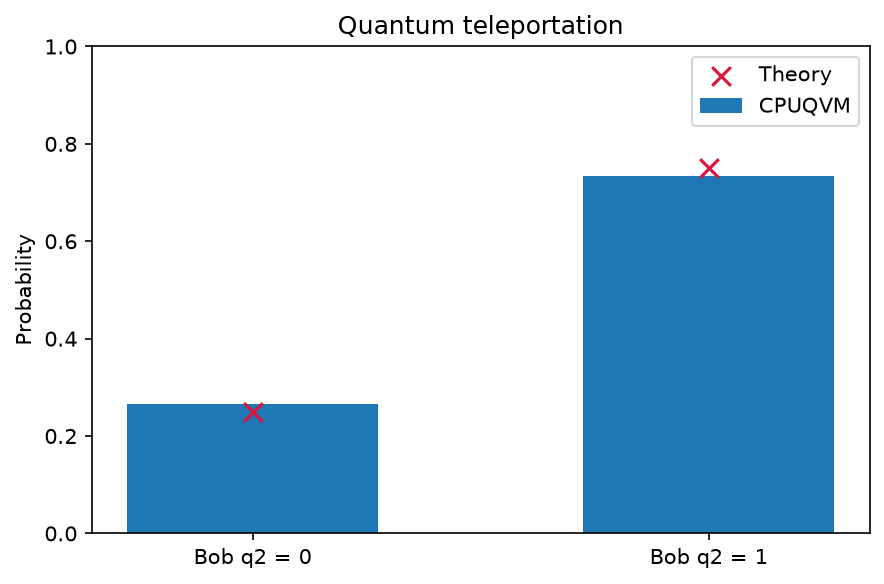

In [8]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([0, 1], [cnt_0 / shots, cnt_1 / shots], width=0.55, label="CPUQVM")
ax.scatter([0, 1], [0.25, 0.75], color="crimson", marker="x", s=80, label="Theory")
ax.set(xticks=[0, 1], xticklabels=["Bob q2 = 0", "Bob q2 = 1"], ylabel="Probability", ylim=(0, 1), title="Quantum teleportation")
ax.legend()
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))
